# PRÁCTICA 3: SISTEMAS DE APOYO A LA DECISIÓN CLÍNICA CON PERCEPTRÓN

### TAREA 1: CARGA Y EXPLORACIÓN DE DATOS

Realizamos la carga del JSON de configuración y del CSV de nuestro grupo (grupo05).

In [4]:
import json

GRUPO = 5  
#Tenemos que subir un nivel para entrar en la carpeta de datos
config_path = f"../datos/grupo_{GRUPO:02d}_config.json"
with open(config_path, encoding="utf-8") as f:
    config = json.load(f)

print("Número de sujetos:", config["n_sujetos"])
print("Patologías:", config["patologias"])
print("Distribución:", config["distribucion_patologias"])
print("Partición:", config["nota_particion"])
print("\nAviso:", config["aviso"])

Número de sujetos: 1000
Patologías: ['infeccion_respiratoria', 'infeccion_urinaria', 'gastroenteritis', 'insuficiencia_cardiaca', 'exacerbacion_respiratoria']
Distribución: {'exacerbacion_respiratoria': 191, 'gastroenteritis': 201, 'infeccion_respiratoria': 209, 'infeccion_urinaria': 197, 'insuficiencia_cardiaca': 202}
Partición: El dataset NO incluye partición predefinida. El alumnado debe dividir los datos en entrenamiento, validación y prueba, justificando los porcentajes elegidos.

Aviso: Datos exclusivamente docentes. No representan criterios clínicos reales. No utilizar para diagnóstico.


In [5]:
import pandas as pd

datos_path = f"../datos/grupo_{GRUPO:02d}_datos.csv"
df = pd.read_csv(datos_path)

print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (1000, 31)


,edad,sexo_masculino,fiebre,tos,disnea,frecuencia_respiratoria,saturacion_o2,disuria,polaquiuria,nitritos,...,tabaquismo,gasometria_ph,pcr,leucocitos_sangre,glucosa,creatinina,temperatura,tas,tad,patologia
0,90,0,0.0,0.0,0.0,16,95.7,0.0,0.0,0.0,...,0.0,7.346,37.9,12.94,82,0.91,38.1,129,74,gastroenteritis
1,27,1,1.0,1.0,0.0,16,100.0,0.0,0.0,0.0,...,0.0,7.440,67.2,10.65,105,0.67,37.2,106,71,gastroenteritis
2,58,0,0.0,1.0,1.0,18,96.0,0.0,0.0,0.0,...,0.0,7.403,69.6,11.61,77,0.50,39.2,115,65,infeccion_respiratoria
3,31,0,0.0,0.0,0.0,16,90.5,0.0,0.0,0.0,...,0.0,7.377,3.4,9.45,128,1.30,38.0,95,75,gastroenteritis
4,64,0,0.0,1.0,1.0,28,87.0,0.0,0.0,0.0,...,0.0,7.343,22.6,11.18,86,1.24,37.7,117,88,exacerbacion_respiratoria


Dimensiones del dataset: (1000, 31), por tanto las filas del CSV coinciden con el número de sujetos del JSON

Generamos tres visualizaciones que exploren la relación entre variables del csv y patología (histogramas, boxplots o diagramas de barras para variables binarias).

Realizamos un diagrama de barras apilado que relaciones el tabaquismo y patología:

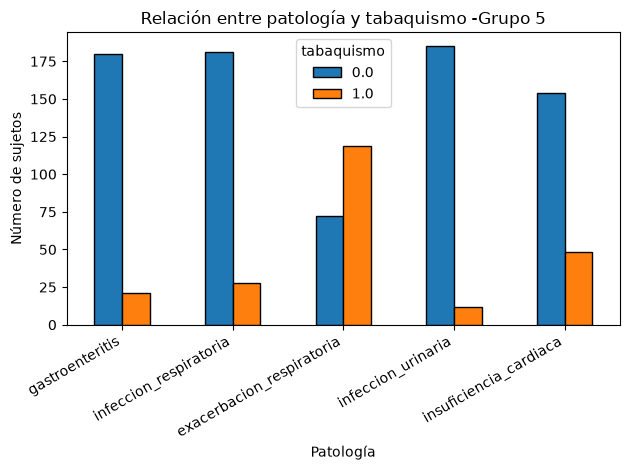

In [6]:
import matplotlib.pyplot as plt

df.value_counts(["patologia", "tabaquismo"]).unstack().plot(kind="bar",  edgecolor="black")

plt.title("Relación entre patología y tabaquismo -Grupo " +str(GRUPO))
plt.xlabel("Patología")
plt.ylabel("Número de sujetos")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


Podemos comprobar que la relación entre patología y tabaquismo es directa en el caso de la excerbacion_respiratoria y el tabaquismo. En el resto de patologías, el tabaquismo no tiene mucha relación.

Ahora realizamos un boxplot entre patología y glucosa.

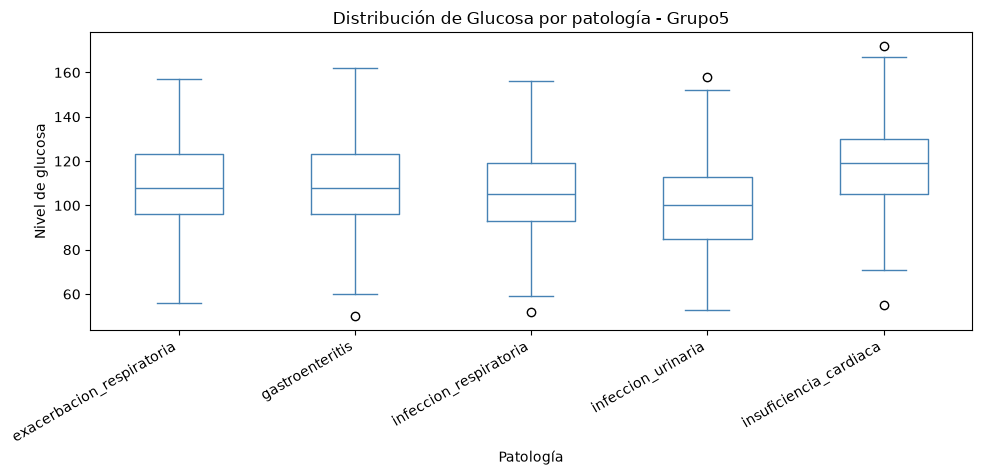

In [7]:
import matplotlib.pyplot as plt

df.boxplot(column="glucosa", by="patologia", figsize=(10, 5), grid=False, color="steelblue")

plt.title("Distribución de Glucosa por patología - Grupo" + str(GRUPO))
plt.suptitle("") 
plt.xlabel("Patología")
plt.ylabel("Nivel de glucosa")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

La insufiencia_cardiaca es la patología con el nivel de glucosa más alto.
La infeccion_urinaria presenta los niveles generales de glucosa más bajos en su rango intercuartílico.
Los outliers representan a pacientes con niveles de glucosa atípicos que se salen del comportamiento general del grupo.

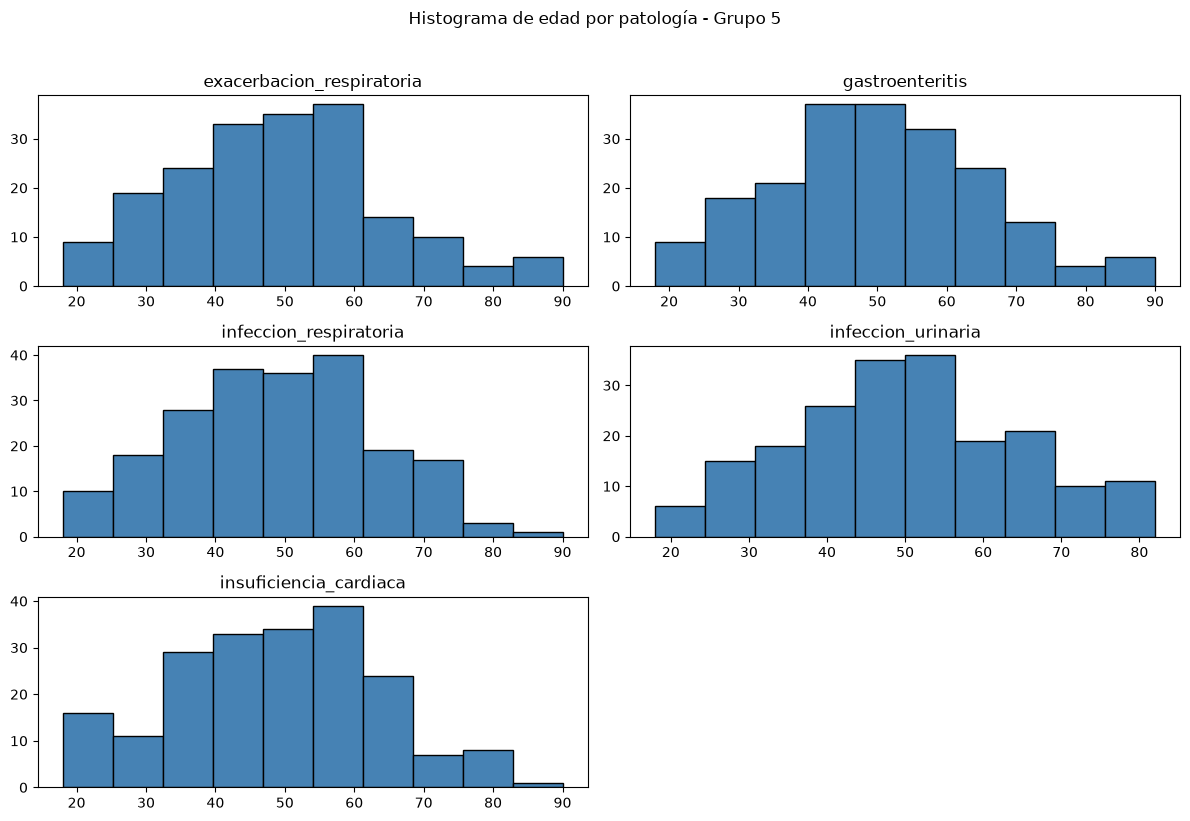

In [8]:
import matplotlib.pyplot as plt

df.hist(column="edad", by="patologia", figsize=(12, 8), color="steelblue", edgecolor="black", grid=False, xrot=0)


plt.suptitle("Histograma de edad por patología - Grupo " + str(GRUPO), y=1.02)
plt.tight_layout()
plt.show()

Estos histogramas representan en el eje x la edad de los pacientes y en el eje y la frecuencia de los mismos. 
En todos podemos ver que la mayoría de personas que sufren estas patologías se encuentran entre los 40-60 años.

### TAREA 2: PREPARACIÓN DE LOS DATOS

División de los datos de entrenamiento, validación y prueba usando train_test_split

Tenemos que tener en cuenta que la variable patología es la variable objetivo.

In [9]:
from sklearn.model_selection import train_test_split

#variables de entrada sin patología
X= df.drop(columns=["patologia"])
#variable objetivo
y= df["patologia"]

#Primera división: 60 % entrenamientoy 40% restante(cada uno con su etiqueta)
X_entrenamiento, X_resto, y_entrenamiento, y_resto = train_test_split(
    X, y, 
    test_size=0.40, 
    stratify=y, 
    random_state=21
)
#Segunda división: 20% validación y 20 % prueba
X_validacion, X_prueba, y_validacion, y_prueba = train_test_split(
    X_resto, y_resto, 
    test_size=0.50, 
    stratify=y_resto, 
    random_state=21
)

In [11]:
#Tamaño de nuestro data set (número de sujetos)
print("Número total de sujetos:", config["n_sujetos"])
#Número de sujetos que quedan en cada subconjunto después de la división
print("Número de sujetos en el conjunto de entrenamiento:", len(X_entrenamiento))
print("Número de sujetos en el conjunto de validación:", len(X_validacion))
print("Número de sujetos en el conjunto de prueba:", len(X_prueba))


Número total de sujetos: 1000
Número de sujetos en el conjunto de entrenamiento: 600
Número de sujetos en el conjunto de validación: 200
Número de sujetos en el conjunto de prueba: 200


Hemos elegido estos porcentajes, reservando una mayor proporción para los datos de entrenamiento para que el modelo disponga de ejemplos suficientes para aprender los patrones asociados a distintas patologías.

El 20% de validación permitirá comparar modelos y ajustar sus hiperparámetros durante el desarrollo. Por otro lado, el 20% reservado para prueba permitirá evaluar el rendimiento final del modelo utilizando datos que no han intervenido en las otras etapas. Este subconjunto es especialmente importante, ya que determinará la fiabilidad de la evaluación final.

Hemos utilizado y= df["patologia"], stratify=y para mantener aproximadamente las proporciones originales de cada patología en los tres subconjuntos, evitando que alguna clase quede ausente.
